# Jude 2026 typing (neural to characters, CTC)

Decodes the neural features of T18's typed sentences into the characters of the cued sentence, the dataset's brain-to-text task. T18 attempts the finger movement of each key in turn, so a sentence trial is a sequence of attempted keystrokes with no per-key timing in the source.

Each trial is one variable-length segment from the go cue to the end of the sentence: a `RaggedSegmenter` triggered on the `Sentence` event reads the two neural streams through `NeuralFeatureExtractor`, and the target is the cued text mapped onto the authors' 30 keys (space, comma, question mark, period, `A`-`Z`) plus the CTC blank. A small convolutional and recurrent network is trained with a CTC loss and scored by character error rate (CER) before any language model.

The split follows the paper's character-error analysis (Fig. 4a-c): train on the calibration and sentence-copy blocks of days 86, 92, 106 and 107 and the calibration blocks of day 93, test on the 100 sentence-copy trials of day 93. One sentence-copy block per training day is held out as the validation set that picks the epoch.

The setup cell builds the Study and calls `download()`, which fetches the data on the first run and returns immediately once the success file exists. It needs a Dryad API key, exported as `NEURALFETCH_DRYAD_TOKEN` or saved in a local `.env` file.

In [1]:
import copy
import re
import string

from dotenv import load_dotenv
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

from neuralshed.dataloader import PadSpec, RaggedCollator, RaggedSegmenter
from neuralshed.datasets.jude_2026_typing import study
from neuralshed.datasets.utils import dataset_dir
from neuralshed.extractors import NeuralFeatureExtractor

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
torch.manual_seed(0)

# reads ./.env into os.environ
load_dotenv()

root = dataset_dir("jude_2026_typing") / "data"
s = study.Jude2026Typing(path=root)
s.download()

# the authors' decoder rate, 10 ms bins compressed to 20 ms
FS = 50.0

# held-out day 93, its 100 sentence-copy trials are the test set
TEST_SESSION = "t18.2025.01.22"

# days 86, 92, 106 and 107
TRAIN_SESSIONS = ("t18.2025.01.15", "t18.2025.01.21", "t18.2025.02.04", "t18.2025.02.05")

# all six arrays, threshold crossings and spike-band power
N_INPUT = 2 * 384

# the authors' CHAR_DEF order (utils/mat_to_tfrecord.py), their '>' written as a space
CHARS = (" ", ",", "?", ".") + tuple(string.ascii_uppercase)

# id 0 is the CTC blank
N_CLASSES = len(CHARS) + 1


def typed_ids(text):
    """The authors' target recipe: keep letters and , ? . , drop the rest, upper-case."""
    kept = re.sub(r"[^a-zA-Z?.,\- ']", "", text)
    kept = kept.replace("--", "").replace(" '", "'").strip().upper()
    return [CHARS.index(c) + 1 for c in kept if c in CHARS]


def decode_ids(ids):
    return "".join(CHARS[i - 1] for i in ids)


def conv_len(n):
    """Output length of one conv with kernel 5, stride 2, padding 2."""
    return (n + 2 * 2 - 5) // 2 + 1


def frame_mask(lengths, n_frames):
    """(B, 1, n_frames) mask that is 1 on each trial's valid frames."""
    return (torch.arange(n_frames)[None, :] < lengths[:, None]).unsqueeze(1).to(torch.float32)


def targets(batch):
    """Padded (B, L) character ids and their lengths from the segment texts."""
    ids = [torch.tensor(typed_ids(t)) for t in batch.metadata["text"]]
    lengths = torch.tensor([len(i) for i in ids])
    return nn.utils.rnn.pad_sequence(ids, batch_first=True), lengths


def levenshtein(a, b):
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (ca != cb))
    return d[-1]


def greedy(logp, n):
    """(T', 31) log-probs over n valid frames to collapsed character ids."""
    out = []
    prev = -1
    for v in logp[:n].argmax(-1).tolist():
        if v != prev and v != 0:
            out.append(v)
        prev = v
    return out


def features(batch):
    """(B, 768, T) features of both streams and the (B, 1, T) valid-frame mask."""
    x = torch.cat([batch.data["tx"], batch.data["sbp"]], dim=1)
    mask = batch.valid_mask("tx").unsqueeze(1).to(x.dtype)
    return x * mask, mask


def centered(batch):
    """Features with their own block mean removed, padded frames kept at zero."""
    x, mask = features(batch)
    mu = torch.stack([block_mean[tl] for tl in batch.metadata["timeline"]]).unsqueeze(-1)
    return (x - mu) * mask, mask


def normalized(batch):
    """(B, 768, T) input: block mean removed, training scale applied, padding at zero."""
    x, mask = centered(batch)
    return x / sd * mask


class CTCDecoder(nn.Module):
    def __init__(self, c_in=N_INPUT, n_classes=N_CLASSES, hidden=192, p=0.3):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv1d(c_in, 256, 5, 2, 2), nn.ReLU(), nn.Dropout(p))
        self.conv2 = nn.Sequential(nn.Conv1d(256, 256, 5, 2, 2), nn.ReLU(), nn.Dropout(p))
        self.gru = nn.GRU(256, hidden, num_layers=2, batch_first=True, bidirectional=True, dropout=p)
        self.head = nn.Linear(2 * hidden, n_classes)

    def forward(self, x, lengths):
        # zero the frames past each trial's valid length, so the next layer sees only padding
        h = self.conv1(x)
        n1 = conv_len(lengths)
        h = h * frame_mask(n1, h.shape[-1])
        h = self.conv2(h)
        n2 = conv_len(n1)
        packed = pack_padded_sequence(h.transpose(1, 2), n2.cpu(), batch_first=True, enforce_sorted=False)
        packed, _ = self.gru(packed)
        h, _ = pad_packed_sequence(packed, batch_first=True, total_length=h.shape[-1])
        return self.head(h).log_softmax(-1), n2


def cer(loader, net):
    """Character error rate: Levenshtein edits over reference characters, summed over trials."""
    net.eval()
    err = 0
    tot = 0
    with torch.no_grad():
        for b in loader:
            logp, n_valid = net(normalized(b), b.lengths["tx"])
            y, y_len = targets(b)
            for k in range(len(n_valid)):
                ref = y[k, : y_len[k]].tolist()
                err += levenshtein(greedy(logp[k], int(n_valid[k])), ref)
                tot += len(ref)
    return err / tot


def subset_loader(ds, mask):
    return DataLoader(ds.select(np.asarray(mask)), batch_size=16, shuffle=False, collate_fn=collate)

2026-10-12 16:29:37 - INFO - neuralset.events.study:463 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/jude_2026_typing/data/Jude2026Typing.


2026-10-12 16:29:38 - INFO - neuralset.events.study:85 - Permissions set for /Volumes/seagate_0/tether/datasets/jude_2026_typing/data/Jude2026Typing (skipped 0 non-owned items).


## 1. T18's calibration and sentence-copy trials

The five sessions of the paper's analysis, loaded through a query on the timeline attributes. Every block is assigned to one split: the test set is the sentence copy of day 93, the validation set is the last sentence-copy block of each training day, and the rest trains. Prompts repeat across days, so the number of test prompts also cued in a training block is printed, and section 6 reports CER with and without them.

In [2]:
sessions = (TEST_SESSION,) + TRAIN_SESSIONS
query = f"session in {list(sessions)} and task_family in ['calibration', 'sentence_copy']"
events = study.Jude2026Typing(path=root, query=query).run()

blocks = events[events.type == "Sentence"].groupby(["session", "task_family"]).block.max()
val_blocks = {(sess, blocks[(sess, "sentence_copy")]) for sess in TRAIN_SESSIONS}
is_test = (events.session == TEST_SESSION) & (events.task_family == "sentence_copy")
is_val = [(sess, blk) in val_blocks for sess, blk in zip(events.session, events.block)]
events["split"] = np.where(is_test, "test", np.where(is_val, "val", "train"))

sentences = events[events.type == "Sentence"]
print("blocks:", events.timeline.nunique(), "| sentence trials:", len(sentences))
display(pd.crosstab([sentences.session, sentences.task_family], sentences.split, margins=True))

train_prompts = set(sentences[sentences.split != "test"].text)
test_sentences = sentences[sentences.split == "test"]
n_seen = int(test_sentences.text.isin(train_prompts).sum())
print(f"test prompts also cued in a training or validation block: {n_seen} of {len(test_sentences)}")

blocks: 66 | sentence trials: 660


split                         test  train  val  All
session        task_family                         
t18.2025.01.15 calibration       0     40    0   40
               sentence_copy     0     80   10   90
t18.2025.01.21 calibration       0     30    0   30
               sentence_copy     0     70   10   80
t18.2025.01.22 calibration       0     30    0   30
               sentence_copy   100      0    0  100
t18.2025.02.04 calibration       0     30    0   30
               sentence_copy     0     90   10  100
t18.2025.02.05 calibration       0     30    0   30
               sentence_copy     0    120   10  130
All                            100    520   40  660

test prompts also cued in a training or validation block: 5 of 100


## 2. One segment per trial

- `tx` and `sbp`: the two streams read separately at 50 Hz, `SpikeCounts` as a rate in Hz and `BandPower` in its native unit, each `(384, T)` over all six arrays.
- the target: the segment's `text` through the authors' recipe, which keeps letters, comma, question mark and period, drops apostrophes and hyphens, and upper-cases the rest (`typed_ids` in the setup cell).

A CTC target needs at least `len(ids) + adjacent repeats` emission frames. Trials shorter than that after the two stride-2 convolutions would be dropped, and the cell reports how many.

In [3]:
# extractor disk cache
CACHE = dict(folder=dataset_dir("jude_2026_typing") / "cache", keep_in_ram=False)

segmenter = RaggedSegmenter(
    extractors={
        "tx": NeuralFeatureExtractor(
            target_unit="Hz",
            event_types=("SpikeCounts",),
            frequency=FS,
            infra=CACHE,
        ),
        "sbp": NeuralFeatureExtractor(
            target_unit="native",
            event_types=("BandPower",),
            frequency=FS,
            infra=CACHE,
        ),
    },
    trigger_query="type == 'Sentence'",
    # each segment inherits its sentence duration
    duration=None,
    metadata_columns=("split", "session", "block", "timeline", "task_family", "text"),
)
dataset = segmenter.apply(events)
dataset.prepare()

frames = np.array([conv_len(conv_len(dataset[i].data["tx"].shape[-1])) for i in range(len(dataset))])
ids = [typed_ids(t) for t in dataset.metadata.text]
need = np.array([len(i) + sum(a == b for a, b in zip(i, i[1:])) for i in ids])
dataset = dataset.select(frames >= need)
print(dataset)
print(f"dropped {int((frames < need).sum())} trials whose emission frames cannot hold the target")
print(f"emission frames per character: median {np.median(frames / need):.1f}")

example = dataset.metadata.text.iloc[0]
print(f"{example!r} -> {decode_ids(typed_ids(example))!r}")

2026-10-12 16:29:39 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


  0%|          | 0/66 [00:00<?, ?it/s]

  2%|▏         | 1/66 [00:00<00:32,  1.98it/s]

  3%|▎         | 2/66 [00:01<00:40,  1.59it/s]

  5%|▍         | 3/66 [00:01<00:36,  1.73it/s]

...

 97%|█████████▋| 64/66 [00:51<00:01,  1.85it/s]

 98%|█████████▊| 65/66 [00:52<00:00,  1.94it/s]

100%|██████████| 66/66 [00:52<00:00,  2.10it/s]

100%|██████████| 66/66 [00:52<00:00,  1.26it/s]

RaggedSegmentDataset(660 segments, extractors: tx, sbp, metadata: split, session, block, timeline, task_family, text)
dropped 0 trials whose emission frames cannot hold the target
emission frames per character: median 9.9
'It just looked liked peanut butter.' -> 'IT JUST LOOKED LIKED PEANUT BUTTER.'


## 3. Normalize: block means, then one scale from the training split

The authors' pipeline subtracts each block's own channel mean and divides by one global standard deviation. A block mean is a label-free statistic of that block's recording, so it is computed for every block, test blocks included. The per-channel scale is computed from the training frames only.

In [4]:
splits = {name: dataset.select(dataset.metadata.split.eq(name).to_numpy()) for name in ("train", "val", "test")}
print({name: len(ds) for name, ds in splits.items()})

collate = RaggedCollator(
    fields={
        "tx": PadSpec(axis=-1, pad_value=0),
        "sbp": PadSpec(axis=-1, pad_value=0),
    }
)
train_loader = DataLoader(splits["train"], batch_size=16, shuffle=True, collate_fn=collate)
val_loader = DataLoader(splits["val"], batch_size=16, shuffle=False, collate_fn=collate)
test_loader = DataLoader(splits["test"], batch_size=16, shuffle=False, collate_fn=collate)


# per-block channel means over the frames of the block's trials
sums = {}
counts = {}
for b in DataLoader(dataset, batch_size=16, shuffle=False, collate_fn=collate):
    x, mask = features(b)
    for k, tl in enumerate(b.metadata["timeline"]):
        sums[tl] = sums.get(tl, 0.0) + x[k].sum(-1)
        counts[tl] = counts.get(tl, 0) + int(mask[k].sum())
block_mean = {tl: sums[tl] / counts[tl] for tl in sums}


# one per-channel scale from the training frames
total_sq = torch.zeros(N_INPUT)
n_frames = 0
for b in train_loader:
    x, mask = centered(b)
    total_sq += (x**2).sum((0, 2))
    n_frames += int(mask.sum())
sd = (total_sq / n_frames).sqrt().view(1, N_INPUT, 1) + 1e-6


{'train': 520, 'val': 40, 'test': 100}


## 4. A compact CTC decoder

Two strided temporal convolutions (50 Hz to 12.5 Hz, one emission frame per 80 ms) feed a 2-layer bidirectional GRU and a per-frame linear head over 31 classes (blank and the 30 keys), read as CTC emissions. The GRU runs on packed sequences, so a trial's emissions do not depend on how much padding its batch carries.

In [5]:
model = CTCDecoder()
print(model)
print("parameters:", sum(p.numel() for p in model.parameters()))

CTCDecoder(
  (conv1): Sequential(
    (0): Conv1d(768, 256, kernel_size=(5,), stride=(2,), padding=(2,))
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
  )
  (conv2): Sequential(
    (0): Conv1d(256, 256, kernel_size=(5,), stride=(2,), padding=(2,))
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
  )
  (gru): GRU(256, 192, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (head): Linear(in_features=384, out_features=31, bias=True)
)
parameters: 2507423


## 5. Train (CTC loss) and pick the epoch on the validation blocks

Validation CER is measured every epoch, and the weights of the best epoch are kept. The test blocks play no part in training or in the choice of epoch.

epoch  5  train CTC 2.257  val CER 0.901


epoch 10  train CTC 0.455  val CER 0.170


epoch 15  train CTC 0.219  val CER 0.154


epoch 20  train CTC 0.132  val CER 0.135


epoch 25  train CTC 0.063  val CER 0.128


epoch 30  train CTC 0.036  val CER 0.119


epoch 35  train CTC 0.025  val CER 0.122


epoch 40  train CTC 0.023  val CER 0.119
kept epoch 28 (val CER 0.112)


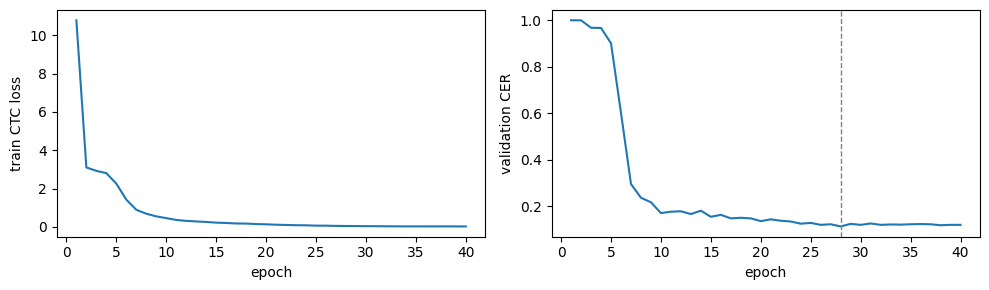

In [6]:
EPOCHS = 40
opt = torch.optim.Adam(model.parameters(), lr=3e-3, weight_decay=1e-5)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, total_steps=EPOCHS * len(train_loader))
ctc = nn.CTCLoss(blank=0, zero_infinity=True)

history = []
best = (np.inf, None, -1)
for ep in range(EPOCHS):
    model.train()
    run = 0.0
    for b in train_loader:
        logp, n_valid = model(normalized(b), b.lengths["tx"])
        y, y_len = targets(b)
        loss = ctc(logp.permute(1, 0, 2), y, n_valid, y_len)
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sched.step()
        run += loss.item()
    val_cer = cer(val_loader, model)
    history.append((ep + 1, run / len(train_loader), val_cer))
    if val_cer < best[0]:
        best = (val_cer, copy.deepcopy(model.state_dict()), ep + 1)
    if (ep + 1) % 5 == 0:
        print(f"epoch {ep + 1:2d}  train CTC {run / len(train_loader):5.3f}  val CER {val_cer:.3f}")

model.load_state_dict(best[1])
print(f"kept epoch {best[2]} (val CER {best[0]:.3f})")

hist = pd.DataFrame(history, columns=["epoch", "train_ctc", "val_cer"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(hist.epoch, hist.train_ctc)
ax[0].set(xlabel="epoch", ylabel="train CTC loss")
ax[1].plot(hist.epoch, hist.val_cer)
ax[1].axvline(best[2], color="gray", ls="--", lw=1)
ax[1].set(xlabel="epoch", ylabel="validation CER")
plt.tight_layout()
plt.show()

## 6. Evaluate on the held-out day

CER on the 100 sentence-copy trials of day 93 with the weights picked on the validation blocks, scored once. The reference point is the empty prediction (CER 1.000), where every reference character counts as one deletion.

In [7]:
test_ds = splits["test"]
unseen = ~test_ds.metadata.text.isin(train_prompts).to_numpy()
scores = {
    f"test, all {len(test_ds)} trials": cer(test_loader, model),
    f"test, {int(unseen.sum())} unseen prompts": cer(subset_loader(test_ds, unseen), model),
    "validation": best[0],
    "train": cer(train_loader, model),
    "baseline (empty)": 1.0,
}
for name, value in scores.items():
    print(f"CER {name:28s}: {value:.3f}")

CER test, all 100 trials        : 0.123
CER test, 95 unseen prompts     : 0.124
CER validation                  : 0.112
CER train                       : 0.005
CER baseline (empty)            : 1.000


## 7. A decoded test trial against its target

cue     : "I think that's a little war condition."
target  : I THINK THATS A LITTLE WAR CONDITION.
decoded : I THINKK THATSHA LITTLEE WAR CINDITION.
CER     : 0.108


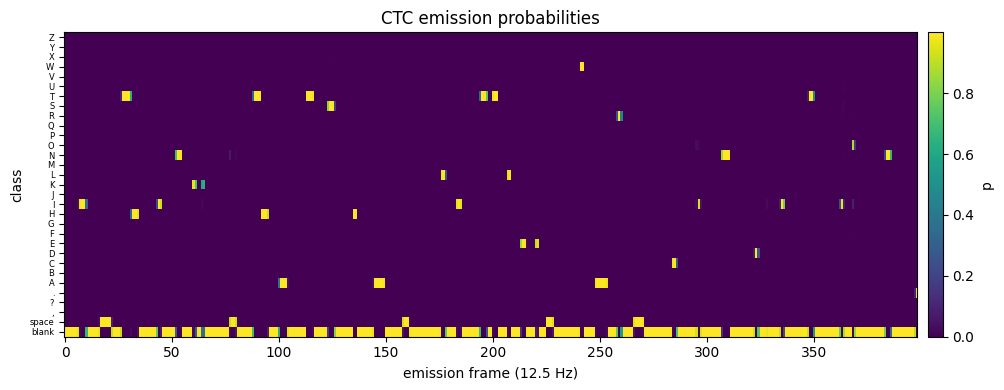

In [8]:
# the test trial with the median CER
model.eval()
rows = []
for i in range(len(test_ds)):
    item = test_ds[i]
    b = collate([item])
    with torch.no_grad():
        logp, n_valid = model(normalized(b), b.lengths["tx"])
    pred = greedy(logp[0], int(n_valid[0]))
    ref = typed_ids(item.metadata["text"])
    rows.append((levenshtein(pred, ref) / len(ref), i, pred, logp[0, : int(n_valid[0])]))
rows.sort(key=lambda r: r[0])
score, i, pred, logp = rows[len(rows) // 2]

print("cue     :", repr(test_ds[i].metadata["text"]))
print("target  :", decode_ids(typed_ids(test_ds[i].metadata["text"])))
print("decoded :", decode_ids(pred))
print(f"CER     : {score:.3f}")

probs = logp.exp().numpy()
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(probs.T, aspect="auto", origin="lower", cmap="viridis", interpolation="none")
ax.set_yticks(range(N_CLASSES))
ax.set_yticklabels(["blank", "space"] + list(CHARS[1:]), fontsize=6)
ax.set(xlabel="emission frame (12.5 Hz)", ylabel="class", title="CTC emission probabilities")
fig.colorbar(im, ax=ax, label="p", pad=0.01)
plt.tight_layout()
plt.show()

## Notes

- CER from a small model trained on four days and scored on a fifth, with greedy decoding and no language model. The paper's decoder passes its character probabilities through the 5-gram language model of `LanguageModels.zip`, which is out of scope here.
- The target is the cued sentence. A trial where T18 mistyped or corrected a key is still scored against the cue.
- Sentence-copy blocks were recorded while the authors' decoder ran on the same features and highlighted its most likely key, calibration blocks without feedback. The test set is closed-loop sentence copy, as in the paper.
- Holding out a day makes the test split block-disjoint but not prompt-disjoint, since prompts repeat across days and datasets (README, Sentences shared with other datasets).
- Possible improvements include the 2.5 s of pre-go context the authors' loader keeps for T18, their 20 ms bin compression, Gaussian smoothing and noise augmentation, the other T18 sessions, a deeper decoder, and a language model.